# One simulation, step by step

This notebook runs one 10-step simulation and shows:

- the setup in separate stages
- the actions printed per step
- the directed ownership graph after each step
- the density evolution across the episode


## Imports


In [11]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from netgraph import Graph

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
import scienceplots

from network_creation.core.agent import Agent
from network_creation.core.environment import Environment
from network_creation.core.model import SchedulingMode
from network_creation.core.simulator import Simulator
from network_creation.observers.action_print_observer import ActionPrintObserver
from network_creation.observers.density_observer import DensityObserver
from network_creation.observers.state_history_observer import StateHistoryObserver
from network_creation.policies.random import RandomPolicy

In [ ]:
plt.rcdefaults()
plt.style.use(style="science")

In [13]:
def build_circle_layout(n_nodes):
    angles = np.linspace(0, 2 * np.pi, n_nodes, endpoint=False)
    return {
        node_id: (float(np.cos(angle)), float(np.sin(angle)))
        for node_id, angle in enumerate(angles)
    }


def build_ownership_graph(ownership_matrix):
    graph = nx.DiGraph()
    n_nodes = ownership_matrix.shape[0]
    graph.add_nodes_from(range(n_nodes))
    for source_node_id, target_node_id in zip(
        *np.nonzero(ownership_matrix), strict=False
    ):
        graph.add_edge(int(source_node_id), int(target_node_id))
    return graph


def compute_subplot_shape(n_plots, max_cols=4):
    n_cols = min(max_cols, max(1, int(np.ceil(np.sqrt(n_plots)))))
    n_rows = int(np.ceil(n_plots / n_cols))
    return n_rows, n_cols

## Environment


In [14]:
initial_ownership = np.array(
    [
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0],
    ],
    dtype=np.int8,
)

env = Environment(initial_ownership, seed=11)
fixed_layout = build_circle_layout(len(env.node_ids))
env.state.ownership_matrix

array([[0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0]], dtype=int8)

## Agents


In [15]:
agents = {
    node_id: Agent(
        id=node_id,
        radius=2,
        policy=RandomPolicy(seed=42 + node_id),
        seed=42 + node_id,
    )
    for node_id in env.node_ids
}

sorted(agents)

[0, 1, 2, 3, 4]

## Simulator settings


In [16]:
mode = SchedulingMode.SEQUENTIAL
max_steps = 10
simulator_seed = 301

(mode, max_steps, simulator_seed)

(<SchedulingMode.SEQUENTIAL: 'SEQUENTIAL'>, 10, 301)

## Observer settings


In [17]:
action_printer = ActionPrintObserver(1)
density_observer = DensityObserver(1)
state_history_observer = StateHistoryObserver(1)

(
    action_printer.__class__.__name__,
    density_observer.__class__.__name__,
    state_history_observer.__class__.__name__,
)

('ActionPrintObserver', 'DensityObserver', 'StateHistoryObserver')

## Run the simulation


In [18]:
simulator = Simulator(
    env=env,
    agents=agents,
    mode=mode,
    max_steps=max_steps,
    seed=simulator_seed,
    observers=[action_printer, density_observer, state_history_observer],
)

simulator.run_episode()

print("current_step:", simulator.current_step)
print("last_modified_step:", simulator.last_modified_step)

step 0: 0 ADD 2
step 1: 1 BRIDGE 3
step 2: 2 BRIDGE 4
step 3: 3 PASS
step 4: 4 ADD 1
step 5: 0 DELETE 2
step 6: 1 DELETE 3
step 7: 2 ADD 0
step 8: 3 DELETE 4
step 9: 4 BRIDGE 3
current_step: 10
last_modified_step: 9


## Directed ownership graph after each step


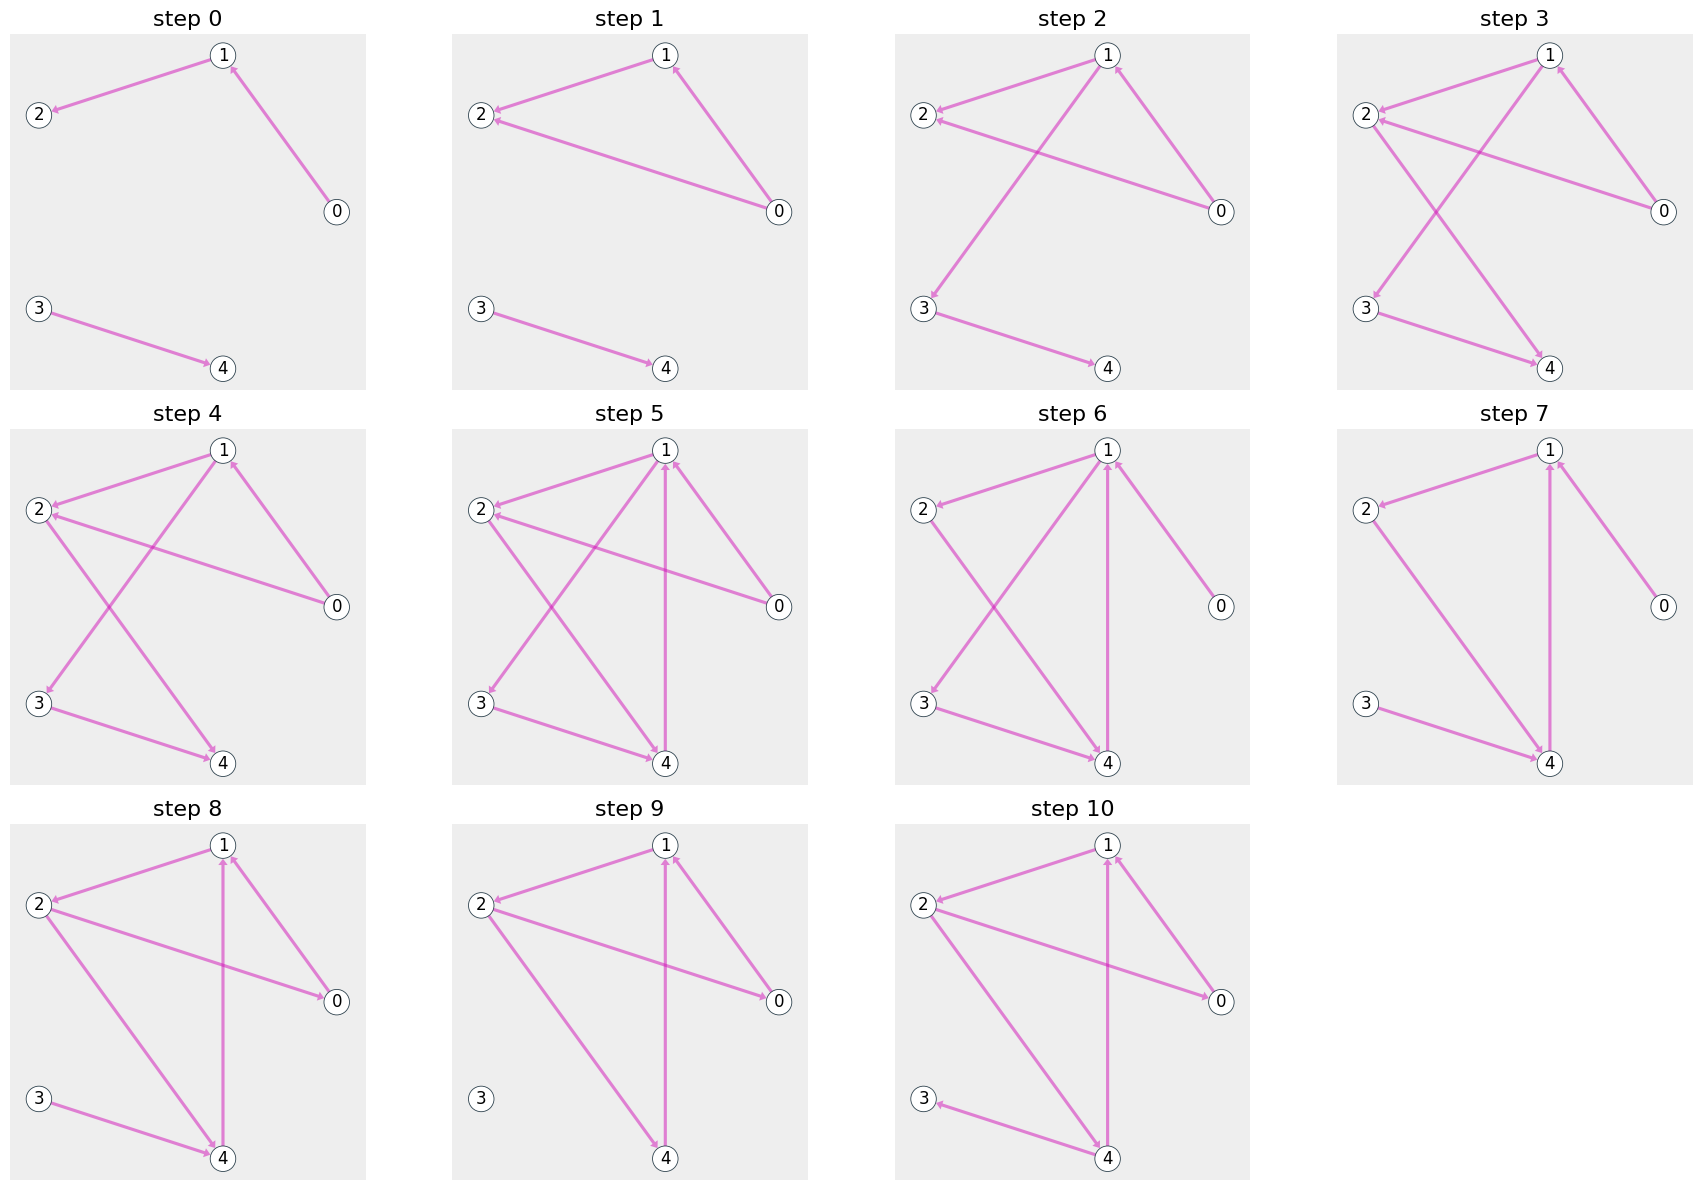

In [19]:
n_plots = len(state_history_observer.steps)
n_rows, n_cols = compute_subplot_shape(n_plots)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax in axes:
    ax.set_facecolor("#eeeeee")
    ax.set_box_aspect(1)

for ax, step, ownership_matrix in zip(
    axes,
    state_history_observer.steps,
    state_history_observer.ownership_matrices,
    strict=False,
):
    directed_graph = build_ownership_graph(ownership_matrix)
    Graph(
        graph=directed_graph,
        node_layout=fixed_layout,
        node_shape="o",
        node_size=8,
        node_labels={node_id: str(node_id) for node_id in directed_graph.nodes},
        node_label_fontdict=dict(size=12, fontweight="normal"),
        edge_layout="straight",
        edge_width=1.9,
        edge_color="#d111b7",
        edge_label_fontdict=dict(
            size=12,
            fontweight="normal",
            color="b",
            bbox=dict(
                boxstyle="round", ec=(1.0, 1.0, 1.0), fc=(1.0, 1.0, 1.0), alpha=0.9
            ),
        ),
        arrows=True,
        ax=ax,
    )
    ax.set_title(f"step {step}")

for ax in axes[n_plots:]:
    ax.remove()

fig.tight_layout()
plt.show()

## Density across the episode


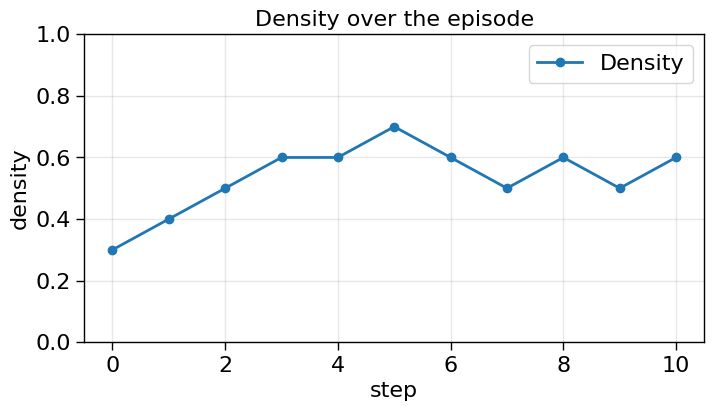

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(
    density_observer.steps,
    density_observer.densities,
    marker="o",
    linewidth=2,
    color="#1f77b4",
    label=density_observer.label,
)
plt.xlabel(density_observer.x_label)
plt.ylabel(density_observer.y_label)
plt.ylim(density_observer.y_min, density_observer.y_max)
plt.title(f"{density_observer.label} over the episode")
plt.grid(alpha=0.3)
plt.legend()
plt.show()